# Hands-on 4: Classification in Machine Learning: Linear Classifiers, The Perceptron
Tutorial paso a paso para implementar un Perceptron en Python con scikit-learn.


**Alumno:** Antonio Valenzuela


## 1. Fundamentos teóricos del Perceptron
- Lo propuso Frank Rosenblatt en 1958, inspirado en la neurona de McCulloch-Pitts.
- Es un clasificador binario lineal y supervisado: separa dos clases con un hiperplano.
- Aprende en línea: cada vez que se equivoca con un ejemplo, mueve el hiperplano para corregirlo.
- Teorema de convergencia: si las clases son linealmente separables, el Perceptron llega a cero errores en un número finito de actualizaciones.
- Limitación: si las clases no son separables con una recta o un plano (como en XOR), nunca converge.

## 2. Modelo matemático y analítico
Entrada neta y salida (función escalón):
$$z=\mathbf w^\top\mathbf x+b,\qquad \hat y=\begin{cases}1 & z\ge 0\\ 0 & z<0\end{cases}$$

Regla de aprendizaje, para cada muestra con tasa de aprendizaje $\eta$:
$$w_j\leftarrow w_j+\eta\,(y-\hat y)\,x_j,\qquad b\leftarrow b+\eta\,(y-\hat y)$$

Si la predicción es correcta, $y-\hat y=0$ y los pesos no cambian. Si falla, los pesos se mueven en la dirección del punto mal clasificado.

La frontera de decisión es el conjunto de puntos con $\mathbf w^\top\mathbf x+b=0$.

## 3. Pipeline de Machine Learning

### 3.0 Importación de librerías

In [ ]:
import numpy as np                                                        # cálculo numérico y números aleatorios
import pandas as pd                                                       # tabla para describir y analizar los datos
import matplotlib.pyplot as plt                                           # gráficas
from sklearn.model_selection import train_test_split                      # divide los datos en entrenamiento y prueba
from sklearn.preprocessing import StandardScaler                          # estandariza las features (media 0, desviación 1)
from sklearn.pipeline import make_pipeline                                # encadena el escalado y el modelo en un solo objeto
from sklearn.linear_model import Perceptron                               # Perceptron de scikit-learn
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)  # métricas de clasificación
np.random.seed(1)                                                         # fija la semilla para que los resultados se repitan

### 3.1 Recolección de datos
No usamos archivo: generamos dos nubes de puntos, una por clase. Así no hace falta subir ningún CSV.

In [ ]:
n = 100                                                                   # número de puntos por clase
clase0 = np.random.normal(loc=[-1.0, -1.0], scale=0.6, size=(n, 2))       # nube de la clase 0, centrada en (-1, -1)
clase1 = np.random.normal(loc=[1.5, 1.5], scale=0.6, size=(n, 2))         # nube de la clase 1, centrada en (1.5, 1.5)
X = np.vstack([clase0, clase1])                                           # apila las dos nubes: matriz de 200 x 2
y = np.array([0] * n + [1] * n)                                           # etiquetas: 0 para la clase 0 y 1 para la clase 1
df = pd.DataFrame(X, columns=["x1", "x2"])                                # convierte las features en una tabla
df["clase"] = y                                                           # agrega la columna con la clase
df.head()                                                                 # muestra las primeras filas

,x1,x2,clase
0,-0.025393,-1.367054,0
1,-1.316903,-1.643781,0
2,-0.480755,-2.380923,0
3,0.046887,-1.456724,0
4,-0.808577,-1.149622,0


### 3.2 Descripción y análisis del dataset

In [ ]:
print("Dimensiones (filas, columnas):", df.shape)                         # cuántas muestras y columnas hay
print(df["clase"].value_counts())                                         # cuántas muestras tiene cada clase
print("Valores nulos:", df.isnull().sum().sum())                          # confirma que no faltan datos
df[["x1", "x2"]].describe().round(2)                                      # media, desviación, mínimo y máximo de cada feature

Dimensiones (filas, columnas): (200, 3)
clase
0    100
1    100
Name: count, dtype: int64
Valores nulos: 0


,x1,x2
count,200.00,200.00
mean,0.30,0.27
std,1.30,1.41
min,-2.11,-2.46
25%,-0.87,-0.98
50%,0.29,0.25
75%,1.43,1.48
max,3.32,2.97


### 3.3 Scatter plot

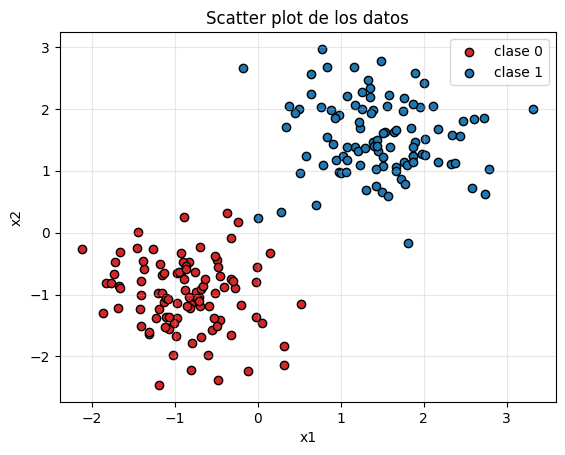

In [ ]:
plt.scatter(clase0[:, 0], clase0[:, 1], c="tab:red", edgecolor="k", label="clase 0")    # puntos de la clase 0 en rojo
plt.scatter(clase1[:, 0], clase1[:, 1], c="tab:blue", edgecolor="k", label="clase 1")   # puntos de la clase 1 en azul
plt.xlabel("x1")                                                          # nombre del eje horizontal
plt.ylabel("x2")                                                          # nombre del eje vertical
plt.title("Scatter plot de los datos")                                    # título de la gráfica
plt.legend(); plt.grid(alpha=.3); plt.show()                              # leyenda, cuadrícula y muestra la figura

Las dos nubes se ven separadas por una recta, así que un Perceptron debería poder separarlas.

### 3.4 División, escalado y Perceptron desde cero
Primero dividimos los datos. El escalador se ajusta solo con entrenamiento para no mezclar información de prueba.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,  # 70 % entrenamiento, 30 % prueba
                                                    random_state=1, stratify=y)  # misma proporción de clases en ambos
sc = StandardScaler().fit(X_train)                                        # calcula media y desviación solo con entrenamiento
X_train_std = sc.transform(X_train)                                       # estandariza el conjunto de entrenamiento
X_test_std = sc.transform(X_test)                                         # aplica la misma transformación a prueba

In [ ]:
class PerceptronDesdeCero:                                                # clase que implementa la regla de Rosenblatt
    def __init__(self, eta=0.1, n_epocas=10, semilla=1):                  # constructor: tasa de aprendizaje, épocas y semilla
        self.eta = eta                                                    # guarda la tasa de aprendizaje η
        self.n_epocas = n_epocas                                          # guarda el número de pasadas sobre los datos
        self.semilla = semilla                                            # guarda la semilla para iniciar los pesos
    def fit(self, X, y):                                                  # método que entrena el modelo
        rgen = np.random.RandomState(self.semilla)                        # generador aleatorio reproducible
        self.w_ = rgen.normal(0, 0.01, X.shape[1])                        # pesos iniciales pequeños y aleatorios
        self.b_ = 0.0                                                     # sesgo inicial en cero
        self.errores_ = []                                                # lista con los errores de cada época
        for _ in range(self.n_epocas):                                    # repite el ciclo por cada época
            errores = 0                                                   # cuenta los errores de esta época
            for xi, yi in zip(X, y):                                      # recorre cada muestra con su etiqueta
                delta = self.eta * (yi - self.predict(xi))                # η (y - ŷ): cero si acierta, ±η si falla
                self.w_ += delta * xi                                     # actualiza los pesos: w ← w + η (y - ŷ) x
                self.b_ += delta                                          # actualiza el sesgo: b ← b + η (y - ŷ)
                errores += int(delta != 0.0)                              # suma 1 si hubo corrección
            self.errores_.append(errores)                                 # guarda los errores de la época
        return self                                                       # devuelve el modelo entrenado
    def net_input(self, X):                                               # calcula la entrada neta z = w·x + b
        return X @ self.w_ + self.b_                                      # producto punto más el sesgo
    def predict(self, X):                                                 # clasifica con la función escalón
        return np.where(self.net_input(X) >= 0.0, 1, 0)                   # 1 si z >= 0, si no 0

In [ ]:
ppn_scratch = PerceptronDesdeCero(eta=0.1, n_epocas=10).fit(X_train_std, y_train)   # entrena con η = 0.1 y 10 épocas
print("Errores por época:", ppn_scratch.errores_)                         # debe llegar a 0 porque los datos son separables
print("Accuracy en prueba:", accuracy_score(y_test, ppn_scratch.predict(X_test_std)))  # proporción de aciertos

Errores por época: [4, 1, 0, 0, 0, 0, 0, 0, 0, 0]
Accuracy en prueba: 0.95


### 3.5 Perceptron con scikit-learn
El `Pipeline` escala los datos y luego entrena el Perceptron, así el escalado solo ve el conjunto de entrenamiento.

In [ ]:
modelo = make_pipeline(StandardScaler(),                                  # paso 1: estandariza las features
                       Perceptron(eta0=0.1, max_iter=100, tol=1e-3, random_state=1))  # paso 2: Perceptron con η = 0.1
modelo.fit(X_train, y_train)                                              # entrena todo el pipeline con los datos de entrenamiento
ppn = modelo.named_steps["perceptron"]                                    # extrae el Perceptron ya entrenado
print("Pesos w:", ppn.coef_[0].round(4), " sesgo b:", ppn.intercept_[0].round(4))  # pesos y sesgo aprendidos
print("Épocas usadas:", ppn.n_iter_)                                      # cuántas épocas necesitó antes de parar

Pesos w: [0.1211 0.1617]  sesgo b: 0.1
Épocas usadas: 6


### 3.6 Evaluación con métricas

Accuracy : 0.95
Precision: 0.9091
Recall   : 1.0
F1-score : 0.9524


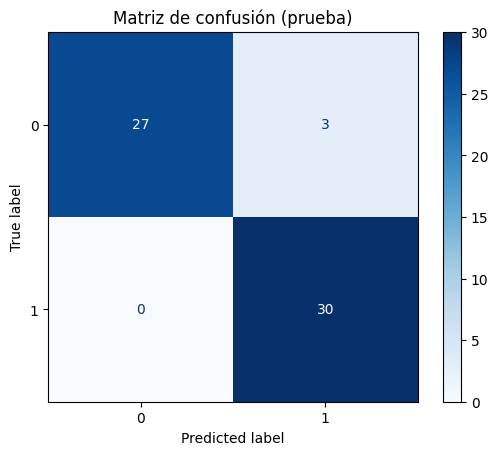

In [ ]:
y_pred = modelo.predict(X_test)                                           # predice la clase de cada muestra de prueba
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))             # proporción de aciertos
print("Precision:", round(precision_score(y_test, y_pred), 4))            # de los predichos clase 1, cuántos lo son
print("Recall   :", round(recall_score(y_test, y_pred), 4))               # de los clase 1 reales, cuántos se detectan
print("F1-score :", round(f1_score(y_test, y_pred), 4))                   # media armónica entre precision y recall
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap="Blues")   # matriz de confusión
plt.title("Matriz de confusión (prueba)"); plt.show()                     # título y muestra la figura

## 4. Conclusiones
- El Perceptron aprende corrigiendo errores. Con datos linealmente separables llega a cero errores de entrenamiento.
- La implementación desde cero y la de scikit-learn siguen la misma regla. La de scikit-learn se encarga del escalado dentro del pipeline.
- Si los datos no son separables, el Perceptron no converge. Por eso se fija un número máximo de épocas.

**Referencias:** Rosenblatt, F. (1958) *The Perceptron*; documentación de scikit-learn, `sklearn.linear_model.Perceptron`.